<a href="https://colab.research.google.com/github/muneeb0065/Deep-Learning/blob/main/MNIST_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [4]:
# The MNIST dataset is already available in keras so we can load it directly

(X_train, y_train), (X_test, y_test) =  keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [7]:
X_train.shape

(60000, 28, 28)

In [8]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [9]:
# Now we will make each pixel in the range of 0 to 1 by dividing by 255 which is the highest pixel value

X_train = X_train/255
X_test = X_test/255

In [10]:
model = Sequential()

model.add(Flatten(input_shape=(28,28))) # As the input is a 2d array so we have changed it to 1d and then passit it
model.add(Dense(100, activation = 'relu'))
model.add(Dense(10,activation= 'softmax')) # As this is a multi class problem so we have used 10 output layers and our activation function is softmax

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(loss= 'sparse_categorical_crossentropy', optimizer='Adam', metrics=['accuracy'])

In [16]:
history = model.fit(X_train,y_train,epochs=15, validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9571 - loss: 0.1458 - val_accuracy: 0.9646 - val_loss: 0.1174
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9705 - loss: 0.1006 - val_accuracy: 0.9678 - val_loss: 0.1059
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9775 - loss: 0.0774 - val_accuracy: 0.9716 - val_loss: 0.0923
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9820 - loss: 0.0595 - val_accuracy: 0.9724 - val_loss: 0.0915
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9852 - loss: 0.0488 - val_accuracy: 0.9735 - val_loss: 0.0932
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9881 - loss: 0.0384 - val_accuracy: 0.9749 - val_loss: 0.0869
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9906 - loss: 0.0316 - val_accuracy: 0.9753 - val_loss: 0.0859
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9927 - loss: 0.0251 - 

In [17]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [18]:
y_pred

array([[2.67221900e-13, 3.86778723e-14, 3.64148434e-10, ...,
        9.99998033e-01, 2.87155993e-11, 1.12182308e-09],
       [2.54669201e-15, 2.28043606e-09, 9.99999940e-01, ...,
        8.86895379e-21, 4.47490101e-10, 5.72914143e-18],
       [4.90042451e-11, 9.99966204e-01, 4.02326987e-06, ...,
        1.57175400e-05, 1.32843461e-05, 2.33219552e-07],
       ...,
       [1.96112413e-19, 7.81975226e-15, 4.54028056e-17, ...,
        5.20732613e-09, 2.96333607e-08, 6.62689854e-04],
       [8.12177728e-19, 5.49892921e-19, 4.95781331e-20, ...,
        1.50760504e-15, 6.34775832e-09, 1.13137688e-16],
       [3.93903417e-11, 2.54927242e-19, 1.24156605e-11, ...,
        1.56652670e-21, 1.52752995e-16, 6.29516633e-16]],
      shape=(10000, 10), dtype=float32)

In [20]:
y_pred = y_pred.argmax(axis=1)

In [21]:
y_pred

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [22]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.973

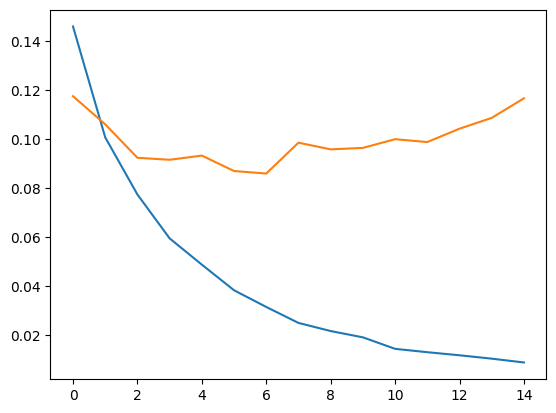

In [24]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

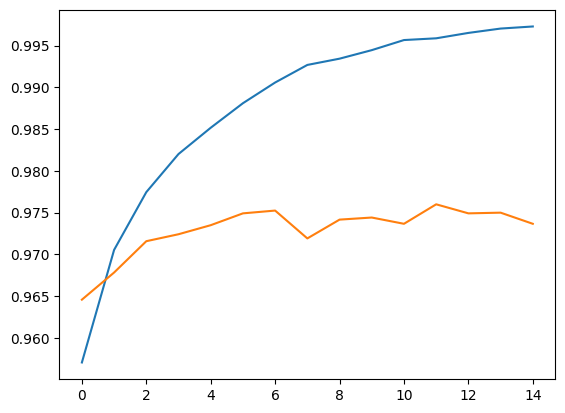

In [25]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

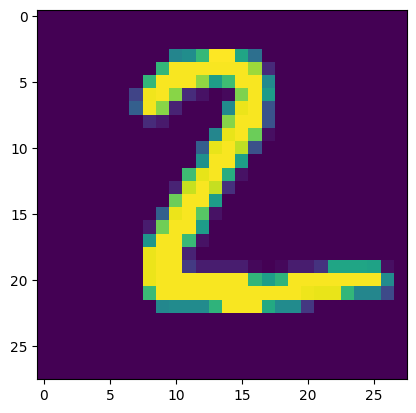

In [26]:
plt.imshow(X_test[1])

In [27]:
model.predict(X_test[1].reshape(1,28,28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


array([2])